# Long static-room test

**Question.** If the room never changes except when a person is present, does the adaptive loop converge to full-frame accuracy at minimal bytes?

**Setup** (`experiments/static_room.py`). One room is replayed 6 times in a row with the tag and server state kept. The loop uses the calibrated 96-pixel online learner (`OnlineLearner(shrink=0.3, threshold='gauss')`) with tiered checks. Rooms: **A** (`training`, `test3`, `test1`, every 2nd frame: 2,301 queries per pass) and the **Mall tile** (2,000 queries per pass). Teachers: FCOS (label-free cutoffs) and true labels (the control). Check schedules:
* `default`: `max_interval=64`, a forced full frame after 4 trusted thumbnails in a row (as `tiered_checks.py`);
* `relaxed`: `max_interval=1024`, `full_every=16`;
* `floor`: as relaxed, and the disagreement rate is reduced by 0.05 (the teacher's expected error) before setting the interval.

**Hypothesis.** The steady-state cost (1–4 kB per query in the switch stream, against a 12-byte code) is set by the check schedule, not by the code.

**Reference.** FCOS on every full frame, on the same frames, answering at the midpoint of its cutoffs: 0.910 balanced accuracy in room A and 0.956 on the Mall tile, at 19,200 bytes per query.

**Caveat.** Passes after the first replay identical frames. That overstates a real static room, where lighting drifts slowly.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('..').resolve()))
from semwisp import piropo
from semwisp.metrics import summary

RES = piropo.REPO / 'results' / 'static_room'
FULL = {'A': 0.910, 'mall': 0.956}                     # FCOS on every full frame, same frames (computed in the session log)
runs = {}
for f in sorted(RES.glob('*.npz')):
    z = np.load(f)
    m = json.loads(str(z['meta']))
    n = len(z['label'])
    runs[m['room'], m['teacher'], m['schedule']] = (m, pd.DataFrame({k: z[k] for k in z.files if k != 'meta' and z[k].shape == (n,)}))
rows = []
for (room, teacher, sched), (m, df) in runs.items():
    for p, g in df.groupby('pass'):
        s = summary(g)
        vc = g[g.explored.astype(bool)].why.value_counts()
        rows.append(dict(room=room, teacher=teacher, schedule=sched, **{'pass': p}, balanced_acc=s['balanced_accuracy'],
                         bytes_per_query=s['up_bytes_per_query'], full_rate=s['full_frame_rate'], thumb_rate=s['thumb_rate'],
                         median_interval=g.interval.median(), resets=int(g.changed.sum()),
                         **{f'full: {r}': int(vc.get(r, 0)) for r in ('bootstrap', 'anomaly', 'unsure', 'disagree', 'floor')}))
T = pd.DataFrame(rows)
(T.set_index(['room', 'teacher', 'schedule', 'pass'])
  .style.format({'balanced_acc': '{:.3f}', 'bytes_per_query': '{:,.0f}', 'full_rate': '{:.1%}', 'thumb_rate': '{:.1%}',
                 'median_interval': '{:.0f}'}))

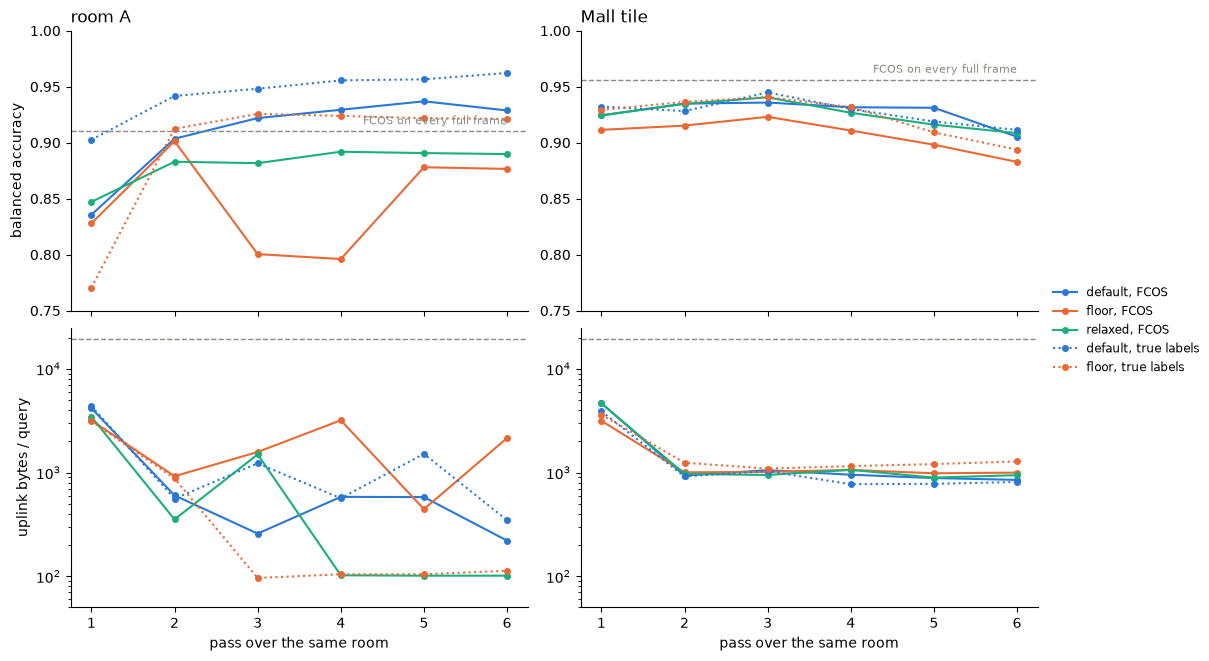

In [2]:
BLUE, ORANGE, AQUA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'
SC = dict(default=BLUE, relaxed=AQUA, floor=ORANGE)
fig, axs = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True, constrained_layout=True)
for j, room in enumerate(['A', 'mall']):
    for (r, teacher, sched), _ in runs.items():
        if r != room:
            continue
        d = T[(T.room == room) & (T.teacher == teacher) & (T.schedule == sched)]
        ls = '-' if teacher == 'fcos' else ':'
        lab = f'{sched}, {"FCOS" if teacher == "fcos" else "true labels"}'
        axs[0, j].plot(d['pass'], d.balanced_acc, color=SC[sched], ls=ls, marker='o', ms=4, label=lab)
        axs[1, j].plot(d['pass'], d.bytes_per_query, color=SC[sched], ls=ls, marker='o', ms=4)
    axs[0, j].axhline(FULL[room], color=GRAY, lw=1, ls='--')
    axs[0, j].text(6, FULL[room] + 0.004, 'FCOS on every full frame', ha='right', va='bottom', fontsize=8, color=GRAY)
    axs[0, j].set_title({'A': 'room A', 'mall': 'Mall tile'}[room], loc='left')
    axs[1, j].set_yscale('log'); axs[1, j].set_ylim(50, 25000)
    axs[1, j].axhline(19200, color=GRAY, lw=1, ls='--'); axs[1, j].axhline(12, color=GRAY, lw=1, ls='--')
    axs[1, j].set_xlabel('pass over the same room')
    for ax in axs[:, j]:
        for s in ('top', 'right'): ax.spines[s].set_visible(False)
axs[0, 0].set_ylabel('balanced accuracy'); axs[1, 0].set_ylabel('uplink bytes / query')
axs[0, 0].set_ylim(0.75, 1.0); axs[0, 1].set_ylim(0.75, 1.0)
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc='outside right center', frameon=False, fontsize=8.5)
plt.show()

## Findings

* **Room A converges, and the check schedule set its floor.** With the relaxed schedule, FCOS teaching: 101 bytes per query from pass 4 on (190× less than a full frame) at 0.890, stable. That is the 12-byte code + thumbnails on 20% of queries (~39 B) + full frames on 0.3% (~58 B). The default schedule ends at 0.929 and 221 B (87× less), above FCOS on every full frame (0.910); with true labels 0.962 at 347 B. So the 1–4 kB of the switch stream is the price of adapting and checking, not of the code.
* **The Mall tile stalls at ~850–1,000 B per query, because of the anomaly trigger.** In the last pass almost every full frame there (77–129 per pass) is fetched because more than 40% of the code's bits were set. That trigger is meant to catch a changed room between checks, but a person crossing the Mall tile sets that many bits as a matter of course. In room A it fires only 2–3 times per pass. The anomaly threshold should be learned per room (e.g. above the share of bits a person usually sets).
* **The `floor` schedule (discounting the teacher's error rate) is unstable.** It stops the server reacting to real disagreement. In room A with FCOS the code went stale and the learner's change detector reset it 5 times (re-bootstraps in passes 2, 3, 4 and 6): 0.80–0.90 at 0.4–3.2 kB. With true labels it is stable (0.921 at 113 B). Don't use it with a noisy teacher.
* **The remaining thumbnails (20–27% of queries) come from uncertain code answers** (|logit| < 2 asks for a thumbnail outside the schedule), not from scheduled checks. They cost ~40–50 B per query; a tighter margin or a per-room calibrated one would cut them.
* **Unexplained: Mall accuracy drifts down over passes** for every schedule and both teachers (e.g. 0.935 → 0.905 FCOS default; 0.945 → 0.911 true labels), although every pass replays identical frames. Something in the learner's state drifts (fading statistics, the calibrated threshold); not yet investigated.
* **Caveat.** Repeated passes replay identical frames, so these are best-case numbers for a static room.